1. Setup and data

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import train_model as tm

data = tm.prepare_data()
print("Train:", data["X_train"].shape, " Test:", data["X_test"].shape)

Train: (200000, 30)  Test: (50000, 30)


2. Compare 4 models and 3 imbalance methods

In [2]:
comparison = tm.compare_models(data)
comparison.round(4)

done: Logistic Regression nothing
done: Logistic Regression class_weight


c:\Users\kapil\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\kapil\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\kapil\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kapil\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\kapil\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

done: Logistic Regression smote
done: Decision Tree nothing
done: Decision Tree class_weight
done: Decision Tree smote
done: Random Forest nothing
done: Random Forest class_weight
done: Random Forest smote
done: XGBoost nothing
done: XGBoost class_weight
done: XGBoost smote


,model,method,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,smote,0.0000,0.0000,0.0000,0.5665,0.0043
1,Logistic Regression,class_weight,0.0026,0.5584,0.0051,0.5751,0.0039
2,Logistic Regression,nothing,0.0000,0.0000,0.0000,0.5629,0.0032
3,Random Forest,nothing,0.0000,0.0000,0.0000,0.5725,0.0026
4,Random Forest,smote,0.0000,0.0000,0.0000,0.5582,0.0026
5,Decision Tree,nothing,0.0000,0.0000,0.0000,0.5950,0.0025
6,XGBoost,nothing,0.0000,0.0000,0.0000,0.5228,0.0025
7,Random Forest,class_weight,0.0028,0.2208,0.0056,0.5354,0.0024
8,Decision Tree,class_weight,0.0019,0.7143,0.0038,0.5294,0.0023
9,XGBoost,smote,0.0000,0.0000,0.0000,0.5082,0.0022


3. Plot

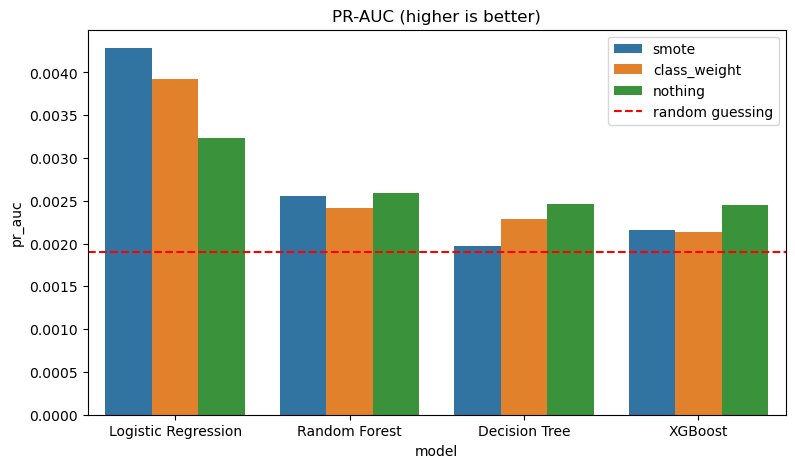

In [3]:
plt.figure(figsize=(9, 5))
sns.barplot(data=comparison, x="model", y="pr_auc", hue="method")
plt.axhline(0.0019, color="red", linestyle="--", label="random guessing")
plt.title("PR-AUC (higher is better)")
plt.legend()
plt.show()

- All ROC-AUC values are between 0.50 and 0.60, and PR-AUC is about 0.002-0.004.
  The red line (random guessing, 0.0019) is almost as high as the bars.
- "nothing": the model says "not fraud" for everything (precision, recall, F1 = 0).
- "class_weight": it finds some fraud, but also flags thousands of normal payments.
- SMOTE did not help.
- Logistic Regression is best, but the differences are very small.

4. Tune the best model

In [4]:
name, model, params, cv_score = tm.tune_best_model(data, comparison)
print("Model:", name)
print("Best settings:", params)
print("CV PR-AUC:", round(cv_score, 4))

tuning: Logistic Regression
Model: Logistic Regression
Best settings: {'C': 0.01}
CV PR-AUC: 0.0025


5. Save the model

In [5]:
result = tm.save_model(data, name, model, params, cv_score, comparison)
print({k: round(v, 4) for k, v in result.items()})

{'precision': 0.0019, 'recall': 0.3958, 'f1': 0.0037, 'roc_auc': 0.488, 'pr_auc': 0.0018}


6. Check the result on test data

In [6]:
import joblib
pipeline = joblib.load(tm.MODEL_PATH)
proba = pipeline.predict_proba(data["X_test_raw"])[:, 1]
pred = (proba >= 0.5).astype(int)

print("[[TN, FP], [FN, TP]]")
print(confusion_matrix(data["y_test"], pred))

[[TN, FP], [FN, TP]]
[[29505 20399]
 [   58    38]]


## Conclusion
- **Selected model:** Logistic Regression with class weights (best CV PR-AUC).
- **Test result:** ROC-AUC about 0.49 and PR-AUC about 0.0018, so it is **not better than random**.
- It catches about 40% of fraud, but flags about 20,000 normal payments (very low precision).
- **Reason:** the features have almost no link to fraud (see the EDA). This is a data problem,
  not a code problem.
- **Next step:** ask if a user id can be added, and check how `fraud_flag` was created.